# Homework 1 Part 2: ~~Gambling~~ Statistics and Simulation
Some stats problem are very complicated and hard to calculate with math alone. To solve this problem, programmers often use simulations instead. By running many experiments in code, we can approximate the underlying statistics without needing to do any calculations.

In this part, we'll simulate ~~Horse Race Betting~~ a game where we guess the winner of a horse race.

To simplify the problem, let's say that the horses will do a 1000 meters race. Each horse have a specific set of stats, listed in horse_stats.csv.
Each stats have the following effect on the horse.
- Speed(m/s) : the speed at which the horse normally starts to run
- Super Start(percent) : Each horse has a [Super Start] % chance of starting with 20% more speed than usual
- Exhaustion(percent) : Each horse has a 30% chance of having its speed lowered by [Exhaustion] % after running for a quarter of the race(250 meters)
- Fall chance(percent) : Every 200 meters of running, each horse have [Fall chance] % chance to fall down. Horses that have fallen down must quit the race. On the offchance that every horse falls down, there is no winner and the house takes all the money.

Betting rules :
- You have 100 UHD(United Horses Dollar).
- If the horse you bet on get 1st place, you will be paid 5x the money
- If the horse you bet on get 2nd place, you will be paid 4x the money
- If the horse you bet on get 3rd place, you will be paid 3x the money

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os

if not os.path.exists("part2_horse_stats.csv"):
    !wget https://raw.githubusercontent.com/PacharaWin/CEDT_stat_data_2024/main/HW1/part2_horse_stats.csv

In [3]:
df = pd.read_csv("part2_horse_stats.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Name         12 non-null     str  
 1   Speed        12 non-null     int64
 2   Super_Start  12 non-null     int64
 3   Exhaustion   12 non-null     int64
 4   Fall_chance  12 non-null     int64
dtypes: int64(4), str(1)
memory usage: 612.0 bytes


In [4]:
# To make this easier to understand, lets split the data in to 5 arrays,
name = df['Name'].to_numpy()
speed = df['Speed'].to_numpy()
super_start = df['Super_Start'].to_numpy()
exhaustion = df['Exhaustion'].to_numpy()
fall_chance = df['Fall_chance'].to_numpy()

In [5]:
name = df['Name'][1]


In [6]:
name

'Gold Ship'

In [7]:
ran = np.random.rand()
ran*100

59.87109044611927

#### TODO 1: Super Start

Hint: This might be helpful https://numpy.org/doc/stable/reference/random/generated/numpy.random.rand.html

In [8]:
def calc_start_speed(speed,super_start):
    # TODO1: Calculate the starting speed of the horse (don't forget super start)
    # Super Start(percent) : Each horse has a [Super Start] % chance of starting with 20% more speed than usual
    # return start_speed, a numpy array with shape (12,) containing the starting speed of each horse

    start_speed = np.zeros(12)

    #### your code here
    for i in range(len(start_speed)):
      ran = np.random.rand()*100
      if(ran < super_start[i]):
        start_speed[i] = speed[i]*1.2
      else:
        start_speed[i] = speed[i]

    ####
    return start_speed

Normal speed: [23 19 19 22 19 20 19 23 22 27 22 21]
Start speed:  [23.  19.  22.8 22.  19.  20.  19.  27.6 22.  32.4 22.  21. ]


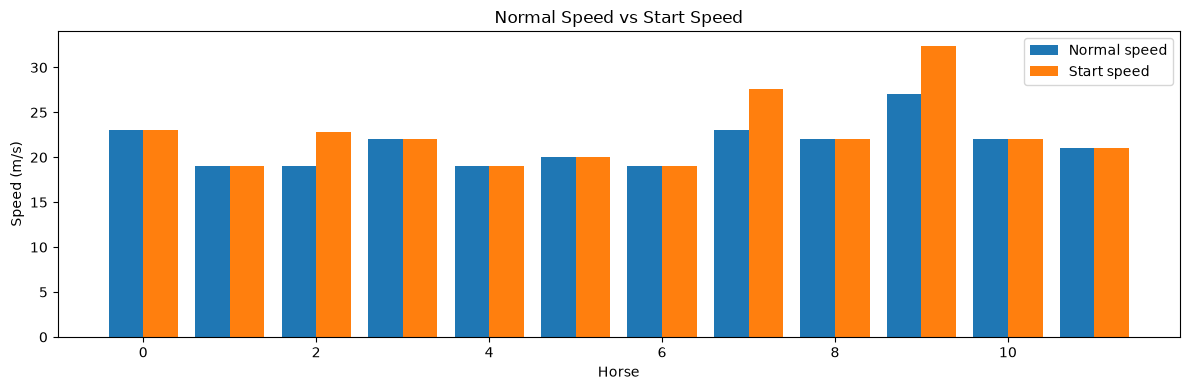

In [9]:
# sanity check 1
np.random.seed(7)
start_speed = calc_start_speed(speed, super_start)

print("Normal speed:", speed)
print("Start speed: ", start_speed)

x = np.arange(len(df))
width = 0.4

plt.figure(figsize=(12, 4))
plt.bar(x - width / 2, speed, width, label="Normal speed")
plt.bar(x + width / 2, start_speed, width, label="Start speed")
plt.title("Normal Speed vs Start Speed")
plt.xlabel("Horse")
plt.ylabel("Speed (m/s)")
#plt.xticks(x, name, rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

#### TODO 2: Exhaustion

In [10]:
quarter_speed = np.zeros((len(speed),4))
quarter_speed[:,0] = start_speed

In [11]:
(len(speed))

12

In [12]:
quarter_speed

array([[23. ,  0. ,  0. ,  0. ],
       [19. ,  0. ,  0. ,  0. ],
       [22.8,  0. ,  0. ,  0. ],
       [22. ,  0. ,  0. ,  0. ],
       [19. ,  0. ,  0. ,  0. ],
       [20. ,  0. ,  0. ,  0. ],
       [19. ,  0. ,  0. ,  0. ],
       [27.6,  0. ,  0. ,  0. ],
       [22. ,  0. ,  0. ,  0. ],
       [32.4,  0. ,  0. ,  0. ],
       [22. ,  0. ,  0. ,  0. ],
       [21. ,  0. ,  0. ,  0. ]])

In [13]:
def calc_quarter_speed(start_speed,exhaustion):
    # TODO2: Calculate the speed after each quarter
    # Exhaustion(percent) : Each horse has a 30% chance of having its speed lowered by [Exhaustion] % after running for a quarter of the race(250 meters)
    # return quarter_speed, a numpy array with shape (12,4) with each column being the speed of each horse in quarter 1,2,3,4

    quarter_speed = np.zeros((len(start_speed),4))
    quarter_speed[:,0] = start_speed

    #### your code here
    for i in range(1,4):
      for j in range(len(start_speed)):
        rt = np.random.rand()*100
        if(rt < 30):
          quarter_speed[j,i] = quarter_speed[j,i-1]*(1-exhaustion[j]/100)


        else:
                quarter_speed[j, i] = quarter_speed[j, i - 1]



    ####
    return quarter_speed

Speed in each quarter:
[[23.        23.        17.25      17.25     ]
 [22.8       22.8       15.96      15.96     ]
 [22.8       20.52      20.52      18.468    ]
 [22.        22.        22.        22.       ]
 [22.8       20.064     17.65632   15.5375616]
 [24.        21.6       21.6       21.6      ]
 [22.8       22.8       22.8       22.8      ]
 [23.        12.65      12.65      12.65     ]
 [22.        22.        22.        22.       ]
 [27.        27.        27.        25.65     ]
 [22.        22.        22.        22.       ]
 [25.2       25.2       25.2       25.2      ]]


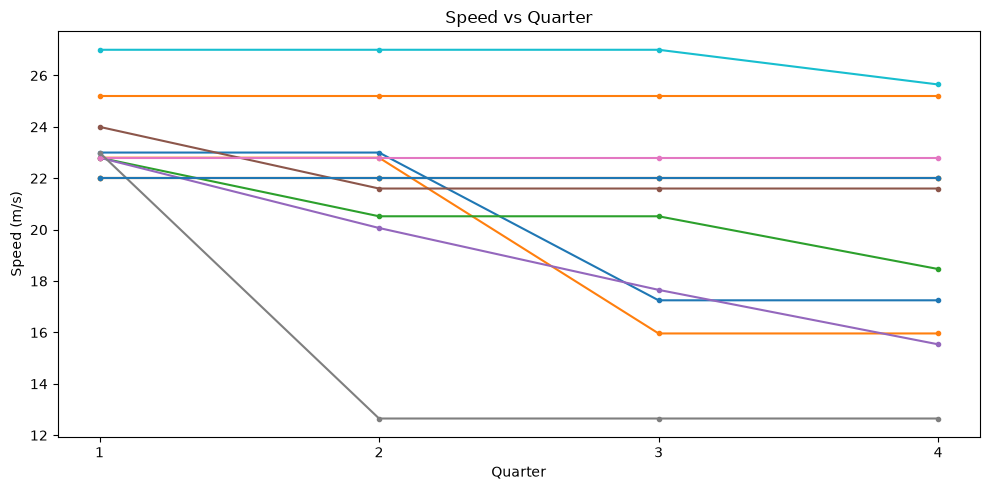

In [14]:
# sanity check 2
# try running the function a few times, speed of some horses should go down as the race goes on.
np.random.seed(11)
start_speed = calc_start_speed(speed, super_start)
quarter_speed = calc_quarter_speed(start_speed, exhaustion)

print("Speed in each quarter:")
print(quarter_speed)

plt.figure(figsize=(10, 5))
plt.plot([1, 2, 3, 4], quarter_speed.T, ".-")
plt.title("Speed vs Quarter")
plt.xlabel("Quarter")
plt.ylabel("Speed (m/s)")
plt.xticks([1, 2, 3, 4])
plt.tight_layout()
plt.show()

#### TODO 3: Fall Chance

In [15]:
# This cell had a TypeError due to a float in range().
# It's not directly part of the solution, so I will comment it out or remove it if I were to clean up.
# For now, I'll just remove the problematic line as it was a test.


In [16]:
def calc_fell_over(fall_chance):
    # TODO3 : Calculate if the horse fell over
    # Fall chance(percent) : Every "200 meters" of running, each horse have [Fall chance] % chance to fall down.
    # return fallen, a numpy array with shape (12,) with containing a boolean(True/False) representing whether each horse fell at any point in the race.

    fallen = np.zeros(12,dtype=bool)

    #### your code here
    for i in range(5):
      for j in range(len(fall_chance)):
        if(np.random.rand()*100 < df['Fall_chance'][j]):
          fallen[j] = True



    ####
    return fallen

In [17]:
# sanity check 3
# Winning Ticket has a high chance to fall, run this code a few times to see if this is true
for i in range(10):
    fallen = calc_fell_over(fall_chance)
    print(fallen[9])

True
True
True
True
True
True
False
False
True
True


In [18]:
def calc_winner(quarter_speed,fallen):
    # this function return a list containing top 3, return empty list if no winner
    quarter_time = 250/quarter_speed
    final_time = np.sum(quarter_time,axis=1)
    rankings = np.argsort(final_time)
    winners = [a for a in rankings if not fallen[a]]
    return winners[:3]
def race(speed,super_start,exhaustion,fall_chance):
    start_speed = calc_start_speed(speed,super_start)
    quarter_speed = calc_quarter_speed(start_speed,exhaustion)
    fallen = calc_fell_over(fall_chance)
    winners = calc_winner(quarter_speed,fallen)
    return winners

In [19]:
# To make this easier to understand, lets split the data in to 5 arrays,
name = df['Name'].to_numpy()
speed = df['Speed'].to_numpy()
super_start = df['Super_Start'].to_numpy()
exhaustion = df['Exhaustion'].to_numpy()
fall_chance = df['Fall_chance'].to_numpy()

#### TODO 4: Histogram
Simulate the race 10000 times, plot the histogram of the number of 1st place for each horse

In [20]:
np.random.seed(0)
first = np.zeros(len(speed),dtype=int)
name = df['Name'].to_numpy()
speed = df['Speed'].to_numpy()
super_start = df['Super_Start'].to_numpy()
exhaustion = df['Exhaustion'].to_numpy()
fall_chance = df['Fall_chance'].to_numpy()
for i in range(10000):
  winner = race(speed,super_start,exhaustion,fall_chance)
  if(len(winner) > 0):
    first[winner[0]] += 1

In [21]:
first

array([1292,  451,  512,  322,  444, 1154,  574, 1320,  579, 1533, 1032,
        787])

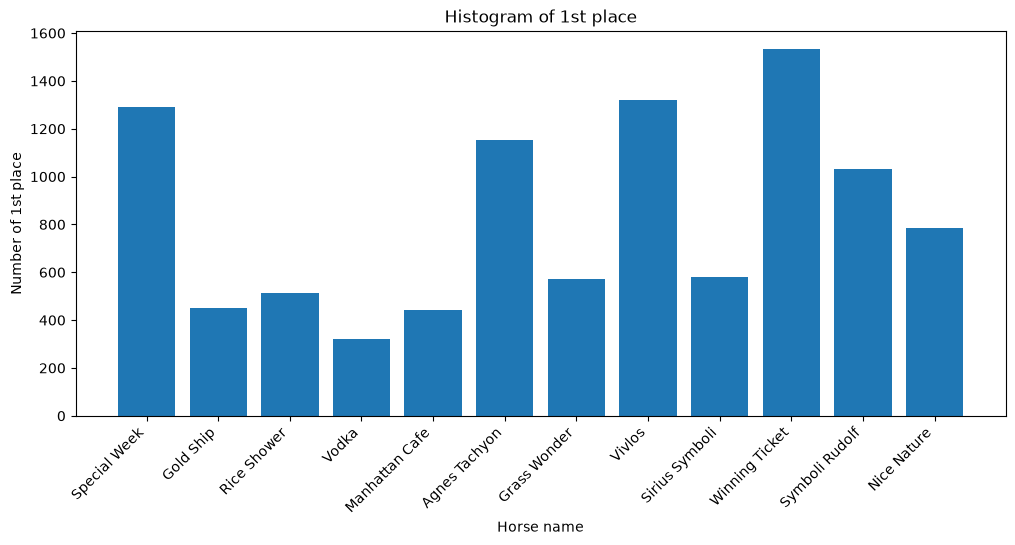

In [22]:
plt.figure(figsize=(12, 5))
plt.bar(name, first)
plt.title("Histogram of 1st place")
plt.xlabel("Horse name")
plt.ylabel("Number of 1st place")
plt.xticks(rotation=45, ha="right")
plt.show()

#### TODO 5: Betting Strategy
We have two betting strategy \
Strategy 1: bet all 100 UHD on horse#9 Winning Ticket \
Strategy 2: split the money into 3 parts, bet each part on horse#6 Grass Wonder, horse#7 Vivlos and horse#8 Sirius Symboli

Simulate the race 10000 times. What is the expected value of the winnings from each strategy?

PS: Betting rules are on the top of this notebook.

In [23]:
np.random.seed(0)
mutiple = [5,4,3]
rank = first = np.zeros((len(speed),3),dtype=int)

for i in range(10000):
    winner = race(speed,super_start,exhaustion,fall_chance)
    if(len(winner)>0):
      for p in range(len(winner)):
        rank[winner[p],p]+=1




In [24]:

rank_table = pd.DataFrame({
    "Horse": name,
    "1st count": rank[:, 0],
    "2nd count": rank[:, 1],
    "3rd count": rank[:, 2],
    "1st probability (%)": rank[:, 0] / 10000 * 100
})

In [25]:
rank_table

,Horse,1st count,2nd count,3rd count,1st probability (%)
0,Special Week,1292,936,373,12.92
1,Gold Ship,451,668,513,4.51
2,Rice Shower,512,1098,1144,5.12
3,Vodka,322,632,1344,3.22
4,Manhattan Cafe,444,1168,1260,4.44
5,Agnes Tachyon,1154,884,558,11.54
6,Grass Wonder,574,1387,1581,5.74
7,Vivlos,1320,1274,557,13.20
8,Sirius Symboli,579,1011,1945,5.79
9,Winning Ticket,1533,80,3,15.33


In [26]:
rank

array([[1292,  936,  373],
       [ 451,  668,  513],
       [ 512, 1098, 1144],
       [ 322,  632, 1344],
       [ 444, 1168, 1260],
       [1154,  884,  558],
       [ 574, 1387, 1581],
       [1320, 1274,  557],
       [ 579, 1011, 1945],
       [1533,   80,    3],
       [1032,  506,  516],
       [ 787,  356,  206]])

In [27]:
mutiple = [5,4,3]
def find_money(r,h,m):
  total_payout = 0
  for hors in h:
    for i in range(3):
      win_per_horse = r[hors,i]
      total_payout += m*mutiple[i]*win_per_horse
  real_payout = total_payout/10000
  return real_payout

#1
find_money(rank,[9],100)
#2
find_money(rank,[6,7,8],100/3)

np.float64(131.00666666666666)

In [28]:
find_money(rank,[9],100)

np.float64(79.94)

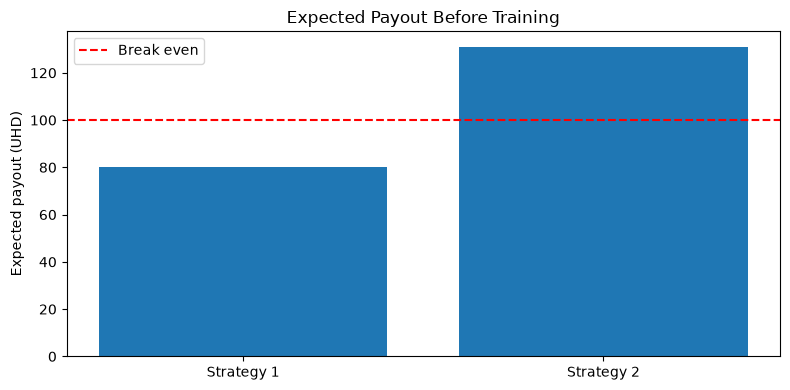

In [29]:
plt.figure(figsize=(8, 4))
plt.bar(
    ["Strategy 1", "Strategy 2"],
    [find_money(rank,[9],100), find_money(rank,[6,7,8],100/3)]
)
plt.axhline(100, color="red", linestyle="--", label="Break even")
plt.title("Expected Payout Before Training")
plt.ylabel("Expected payout (UHD)")
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
np.random.seed(0)

n_simulations = 10000

score = np.zeros(2)

for i in range(n_simulations):
    winners = race(speed, super_start, exhaustion, fall_chance)

    if len(winners) == 0:
        continue

    first_place = winners[0]

    if first_place == 9:
        score[0] += 1
    bet_each = 100 / 3

    if first_place == 6:
         score[1] += 1
    elif first_place == 7:
        score[1] += 1
    elif first_place == 8:
       score[1] += 1

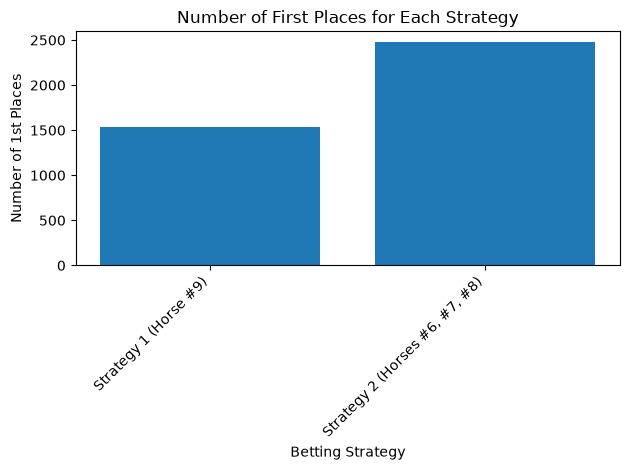

In [31]:
plt.bar(np.arange(len(score)), score)
plt.title("Number of First Places for Each Strategy")
plt.xlabel("Betting Strategy")
plt.ylabel("Number of 1st Places")
plt.xticks(np.arange(len(score)), ['Strategy 1 (Horse #9)', 'Strategy 2 (Horses #6, #7, #8)'], rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Optional: Master Strategist
Could you explain why going all in on #9 (who has the highest chance of getting 1st) is worse than betting on #7 (who has lower chance of getting 1st than #9) + #6 and #8 (who have even lower chance of getting 1st)

hint: you might want to plot a few more histogram :)

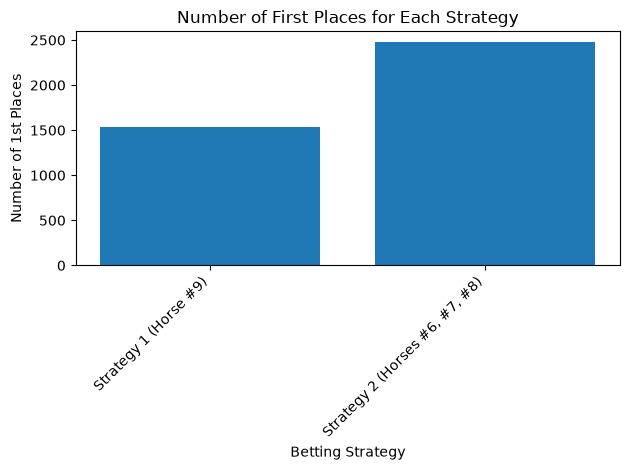

In [32]:
# Your code here
plt.bar(np.arange(len(score)), score)
plt.title("Number of First Places for Each Strategy")
plt.xlabel("Betting Strategy")
plt.ylabel("Number of 1st Places")
plt.xticks(np.arange(len(score)), ['Strategy 1 (Horse #9)', 'Strategy 2 (Horses #6, #7, #8)'], rotation=45, ha='right')
plt.tight_layout()
plt.show()

After the release of ***Uma Musume: Cinderella Gray***, all horses began practicing ***The Triumphant Pulse***, a technique that greatly increases speed during the final stretch of the race, inspired by ***Oguri Cap***. Now, in the last quarter of every race, each horse has a [accelerate_chance]% chance to gain a 30% speed boost. Among them, Winning Ticket trained the hardest and has the highest chance of activating this skill in real competitions.





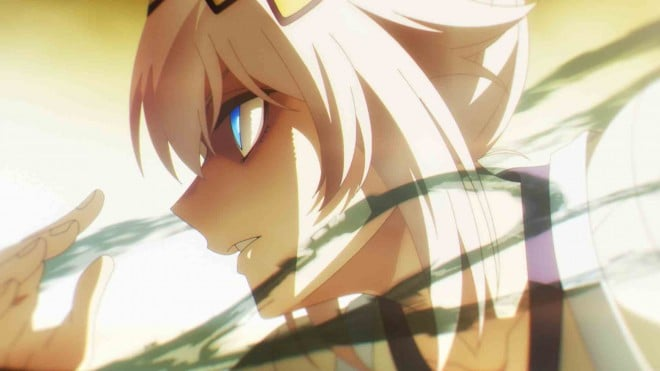



In [33]:
acceralate_chances = np.array([10, 7, 22, 30, 5, 15, 3, 12, 16, 90, 15, 42])

#### TODO 6: Recalculate each horse's quarter speed after training for The Triumphant Pulse

In [34]:
from re import L
def recalc_quarter_speed(start_speed, exhaustion, acceralate):
    # TODO6: Calculate the speed after each quarter
    # accelerate (percent): Each horse has a [accelerate]% chance to trigger The Triumphant Pulse,
    # which boosts its speed by 30% during the final quarter of the race (last 250 meters).
    # If a horse activates this skill, it will not be affected by exhaustion in that quarter.
    # return quarter_speed, a numpy array with shape (12,4) with each column being the speed of each horse in quarter 1,2,3,4
    quarter_speed = np.zeros((len(speed),4))
    quarter_speed[:,0] = start_speed

    #### your code here
    for i in range(1,4):
      for j in range(len(speed)):
        if(i==3 and np.random.rand() *100 < acceralate_chances[j]):
          quarter_speed[j,i] = quarter_speed[j,i-1]*1.3
        elif np.random.rand() * 100 < 30:
                quarter_speed[j, i] = (
                    quarter_speed[j, i - 1]
                    * (1 - exhaustion[j] / 100)
                )
        else:
          quarter_speed[j,i] = quarter_speed[j,i-1]


    ####
    return quarter_speed

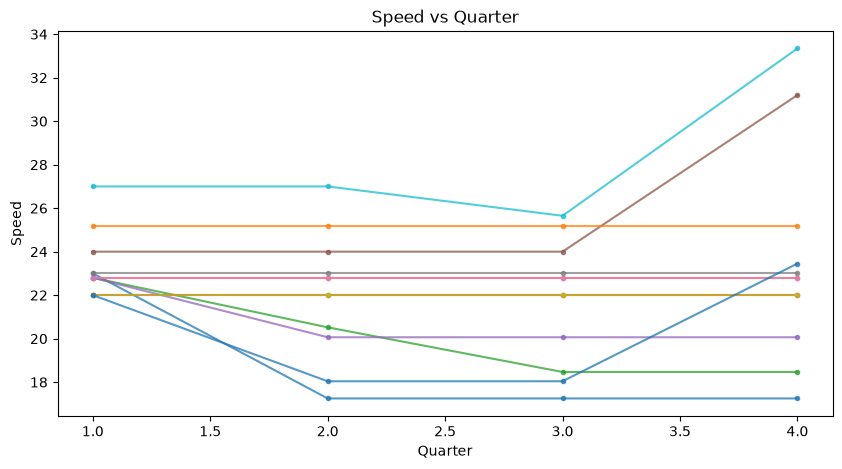

In [35]:
# sanity check again
# Think: What output do you expect to see here?
quarter_speed = recalc_quarter_speed(start_speed, exhaustion, acceralate_chances)
fig, ax = plt.subplots(figsize=(10, 5))
plt.plot(range(1,5),quarter_speed.T,'.-', alpha=0.75)
plt.title("Speed vs Quarter")
plt.xlabel("Quarter")
plt.ylabel("Speed")
plt.show()

In [36]:
quarter_speed

array([[23.   , 17.25 , 17.25 , 17.25 ],
       [22.8  , 22.8  , 22.8  , 22.8  ],
       [22.8  , 20.52 , 18.468, 18.468],
       [22.   , 22.   , 22.   , 22.   ],
       [22.8  , 20.064, 20.064, 20.064],
       [24.   , 24.   , 24.   , 31.2  ],
       [22.8  , 22.8  , 22.8  , 22.8  ],
       [23.   , 23.   , 23.   , 23.   ],
       [22.   , 22.   , 22.   , 22.   ],
       [27.   , 27.   , 25.65 , 33.345],
       [22.   , 18.04 , 18.04 , 23.452],
       [25.2  , 25.2  , 25.2  , 25.2  ]])

#### TODO 7: Rerun the Experiment again
Re-run the experiment from TODO 5 after applying The Triumphant Pulse training to all horses.  
Does this change which betting strategy is more favorable? Explain why.

In [37]:
np.random.seed(0)
# Your code here
name = df['Name'].to_numpy()
speed = df['Speed'].to_numpy()
super_start = df['Super_Start'].to_numpy()
exhaustion = df['Exhaustion'].to_numpy()
fall_chance = df['Fall_chance'].to_numpy()
def race(speed,super_start,exhaustion,fall_chance,acceralate):
    start_speed = calc_start_speed(speed,super_start)
    quarter_speed = recalc_quarter_speed(start_speed,exhaustion,acceralate)
    fallen = calc_fell_over(fall_chance)
    winners = calc_winner(quarter_speed,fallen)
    return winners


horse = np.zeros(len(speed), dtype=int)

for i in range(10000):
  winner = race(speed,super_start,exhaustion,fall_chance,acceralate_chances)
  if(len(winner)>0):
      horse[winner[0]]+=1


In [38]:
horse

array([ 937,  300,  614,  833,  324, 1082,  403, 1131,  859, 1629, 1022,
        866])

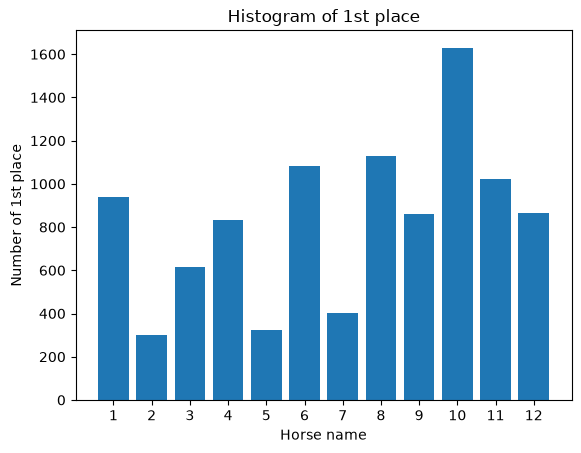

In [39]:



plt.bar(range(1, len(speed) + 1), horse)
plt.title("Histogram of 1st place")
plt.xlabel("Horse name")
plt.ylabel("Number of 1st place")
plt.xticks(range(1, len(speed) + 1))
plt.show()

In [40]:
def race_with_pulse(
    speed,
    super_start,
    exhaustion,
    fall_chance,
    accelerate_chances
):
    start_speed = calc_start_speed(speed, super_start)
    quarter_speed = recalc_quarter_speed(
        start_speed,
        exhaustion,
        accelerate_chances
    )
    fallen = calc_fell_over(fall_chance)
    winners = calc_winner(quarter_speed, fallen)

    return winners
np.random.seed(0)

pulse_finish_counts = np.zeros((len(speed), 3), dtype=int)
pulse_no_winner_count = 0
acceralate_chances = np.array([10, 7, 22, 30, 5, 15, 3, 12, 16, 90, 15, 42])
for simulation in range(10000):
    winners = race_with_pulse(
        speed,
        super_start,
        exhaustion,
        fall_chance,
        acceralate_chances
    )

    if len(winners) == 0:
        pulse_no_winner_count += 1
    else:
        for place in range(len(winners)):
            horse_id = winners[place]
            pulse_finish_counts[horse_id, place] += 1



pulse_strategy1_payout = find_money(
    pulse_finish_counts,
    [9],
    100
)
pulse_strategy2_payout = find_money(
    pulse_finish_counts,
    [6, 7, 8],
    100 / 3
)
pulse_strategy1_profit = pulse_strategy1_payout - 100
pulse_strategy2_profit = pulse_strategy2_payout - 100

print("Strategy 1 expected winnings:", pulse_strategy1_payout)
print("Strategy 2 expected winnings:", pulse_strategy2_payout)

Strategy 1 expected winnings: 82.96
Strategy 2 expected winnings: 120.64666666666668


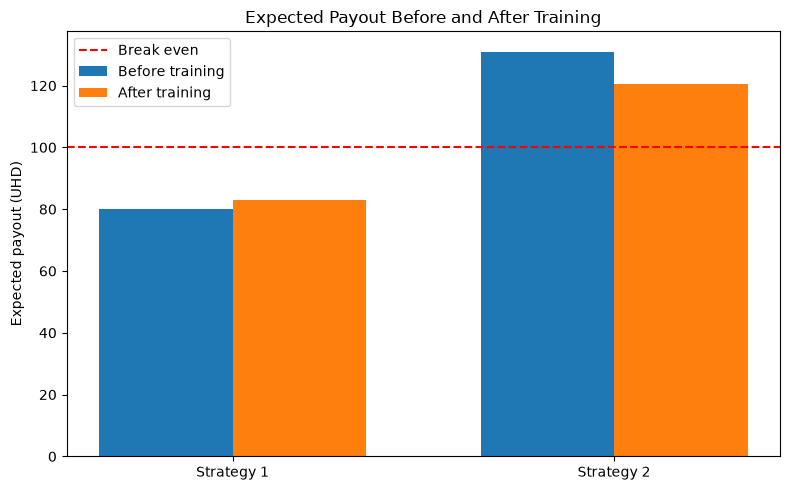

In [41]:
before_payout = [find_money(rank,[9],100), find_money(rank,[6,7,8],100/3)]
after_payout = [pulse_strategy1_payout, pulse_strategy2_payout]
x = np.arange(2)
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width / 2, before_payout, width, label="Before training")
plt.bar(x + width / 2, after_payout, width, label="After training")
plt.axhline(100, color="red", linestyle="--", label="Break even")
plt.xticks(x, ["Strategy 1", "Strategy 2"])
plt.ylabel("Expected payout (UHD)")
plt.title("Expected Payout Before and After Training")
plt.legend()
plt.tight_layout()
plt.show()